# Activity 1: Dataset Preparation (Titanic)
**Course:** Machine Learning | **Class:** T.Y. B.Tech AI & DS, Division A

## 1. Dataset Information
- **Name:** Titanic Dataset
- **Source:** Kaggle – https://www.kaggle.com/c/titanic/data
- **File type:** CSV (`titanic.csv`)
- **Rows x Columns:** 891 x 12
- **What it represents:** Details of passengers on the Titanic (class, sex, age, fare, etc.) and whether each passenger survived.
- **Future target column:** `Survived` (0 = No, 1 = Yes). We only prepare the data here; no model is built.

## 2. Load the Dataset

In [7]:
%pip install seaborn
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("titanic.csv")
df_original = df.copy()   # untouched copy of the raw data
print("Shape:", df.shape)

Shape: (891, 12)


## 3. Inspect the Dataset

In [8]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 66.2 KB


In [11]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Numerical and Categorical Columns

In [12]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
print("Numerical  :", num_cols)
print("Categorical:", cat_cols)

Numerical  : ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


## 4. Data Quality Checks

In [13]:
missing = df.isnull().sum()
percent = (missing / len(df) * 100).round(2)
print(pd.DataFrame({"Missing": missing, "Percent (%)": percent}))
print("\nDuplicates:", df.duplicated().sum())

             Missing  Percent (%)
PassengerId        0         0.00
Survived           0         0.00
Pclass             0         0.00
Name               0         0.00
Sex                0         0.00
Age              177        19.87
SibSp              0         0.00
Parch              0         0.00
Ticket             0         0.00
Fare               0         0.00
Cabin            687        77.10
Embarked           2         0.22

Duplicates: 0


### Category Consistency Check (Sex, Embarked)

In [14]:
for col in ["Sex", "Embarked"]:
    print(col, "->", df[col].unique())
    print("Extra spaces:", (df[col].dropna() != df[col].dropna().str.strip()).sum())
    print()

Sex -> <StringArray>
['male', 'female']
Length: 2, dtype: str
Extra spaces: 0

Embarked -> <StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str
Extra spaces: 0



Labels are consistent: no spelling variants and no extra spaces.

## 5. Exploratory Data Analysis (EDA)

In [15]:
print(df[["Age", "Fare"]].describe())
print()
print(df["Embarked"].value_counts())
print()
print(df["Sex"].value_counts())

              Age        Fare
count  714.000000  891.000000
mean    29.699118   32.204208
std     14.526497   49.693429
min      0.420000    0.000000
25%     20.125000    7.910400
50%     28.000000   14.454200
75%     38.000000   31.000000
max     80.000000  512.329200

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

Sex
male      577
female    314
Name: count, dtype: int64


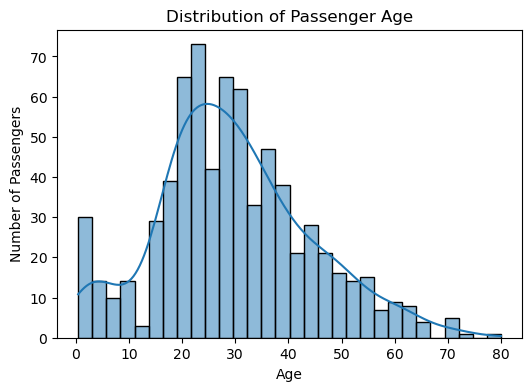

In [16]:
plt.figure(figsize=(6,4))
sns.histplot(df["Age"].dropna(), bins=30, kde=True)
plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

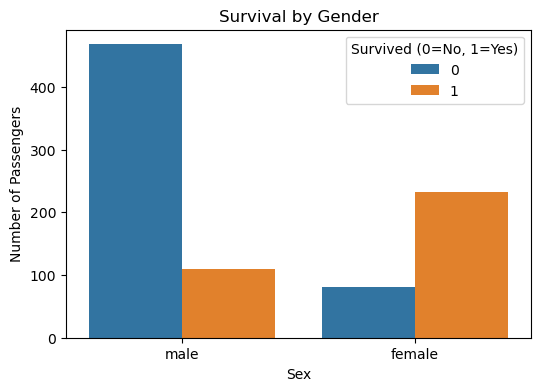

In [17]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Sex", hue="Survived")
plt.title("Survival by Gender")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived (0=No, 1=Yes)")
plt.show()

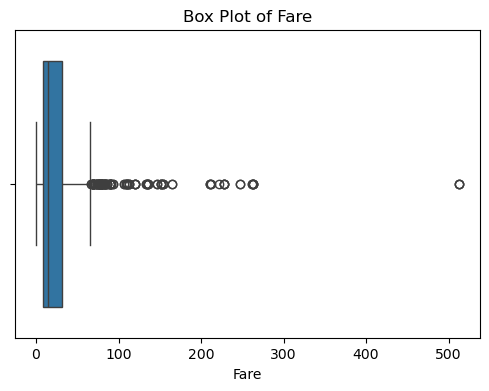

In [18]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["Fare"])
plt.title("Box Plot of Fare")
plt.xlabel("Fare")
plt.show()

### Observations
1. Most passengers are aged roughly 20–40; very few are above 60.
2. Many more females survived than males, so `Sex` is likely an important feature.
3. `Fare` is highly right-skewed with several large outliers (very expensive tickets). Fare also has a much larger range than other columns, so it needs scaling.

## 6. Data Cleaning

In [19]:
df = df.drop_duplicates()                          # no duplicates found, kept for safety
df = df.drop(columns=["Cabin"])                    # ~77% missing
df["Age"] = df["Age"].fillna(df["Age"].median())   # median is robust to outliers
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


**Why these methods:** `Age` has outliers and is skewed, so the median is safer than the mean. `Embarked` is categorical, so the mode is used. `Cabin` is about 77% empty, so it is dropped instead of filled. Rows with missing values were not deleted, to avoid losing data.

`Name` and `Ticket` are identifiers with no predictive pattern, so they are dropped.

In [20]:
df = df.drop(columns=["Name", "Ticket"])

## 7. Encode Categorical Data
`Sex` and `Embarked` are nominal (no natural order), so one-hot encoding is used. `drop_first=True` removes one redundant column per feature.

In [21]:
print("Before encoding:")
print(df[["Sex", "Embarked"]].head())

Before encoding:
      Sex Embarked
0    male        S
1  female        C
2  female        S
3  female        S
4    male        S


In [22]:




df = pd.get_dummies(df, columns=["Sex", "Embarked"], drop_first=True, dtype=int)
df.head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,1,0,3,22.0,1,0,7.2500,1,0,1
1,2,1,1,38.0,1,0,71.2833,0,0,0
2,3,1,3,26.0,0,0,7.9250,0,0,1
3,4,1,1,35.0,1,0,53.1000,0,0,1
4,5,0,3,35.0,0,0,8.0500,1,0,1


## 
8. Feature Scaling
Scaling matters for algorithms that depend on distances or gradients (KNN, SVM, logistic regression, gradient descent), because a feature with a big range would dominate the others. `Age` and `Fare` are on very different scales (Age ≈ 0–80, Fare ≈ 0–512), so we apply **Standardization**. `PassengerId` is only an ID, `Survived` is the target, and the encoded columns are already 0/1, so they are **not** scaled.

In [23]:
from sklearn.preprocessing import StandardScaler

scale_cols = ["Age", "Fare"]
df[scale_cols] = StandardScaler().fit_transform(df[scale_cols])
print(df[scale_cols].describe().round(2))

          Age    Fare
count  891.00  891.00
mean     0.00    0.00
std      1.00    1.00
min     -2.22   -0.65
25%     -0.57   -0.49
50%     -0.10   -0.36
75%      0.43   -0.02
max      3.89    9.67


## 9. Final Verification

In [24]:
print("Final shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
df.sample(5, random_state=42)

Final shape: (891, 10)
Missing values: 0
Duplicates: 0


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
709,710,1,3,-0.104637,1,1,-0.341452,1,0,0
439,440,0,2,0.125912,0,0,-0.437007,1,0,1
840,841,0,3,-0.719436,0,0,-0.488854,1,0,1
720,721,1,2,-1.795334,0,1,0.016023,0,0,1
39,40,1,3,-1.180535,1,0,-0.422074,0,0,0


## 10. Save the Prepared Dataset

In [25]:
df.to_csv("titanic_prepared.csv", index=False)
print("Saved titanic_prepared.csv")

Saved titanic_prepared.csv


## 11. Conclusion
The Titanic data had missing values in `Age` (177), `Cabin` (687) and `Embarked` (2), and no duplicates. `Cabin` was dropped, `Age` was filled with the median and `Embarked` with the mode. `Name` and `Ticket` were removed, `Sex` and `Embarked` were one-hot encoded, and `Age` and `Fare` were standardized. The final dataset has no missing values or duplicates and is ready for model building.